In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


np.random.seed(42)


In [89]:

def load_power_plant_data(filename, sheet_name="Sheet1"):
    """
    Features:
        AT : Ambient Temperature
        V  : Exhaust Vacuum
        AP : Ambient Pressure
        RH : Relative Humidity

    Target:
        PE : Net electrical energy output
    """

    data = pd.read_excel(filename, sheet_name=sheet_name)

    feature_names = ["AT", "V", "AP", "RH"]
    target_name = "PE"

    X = data[feature_names].values.astype(float)
    y = data[target_name].values.astype(float)

    return X, y, feature_names, target_name, data


In [90]:

X_all, y_all, feature_names, target_name, power_data = load_power_plant_data(
    "data_02a.xlsx",
    sheet_name="Sheet1"
)

print("Dataset loaded.")
print("Number of samples:", len(y_all))
print("Number of features:", X_all.shape[1])

print("\nFirst 5 rows:")
print(power_data.head())


Dataset loaded.
Number of samples: 9568
Number of features: 4

First 5 rows:
      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90


In [91]:
print("Dataset shape:", power_data.shape)
print("\nMissing values:")
print(power_data.isnull().sum())
print("\nSummary statistics:")
print(power_data.describe())


Dataset shape: (9568, 5)

Missing values:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Summary statistics:
                AT            V           AP           RH           PE
count  9568.000000  9568.000000  9568.000000  9568.000000  9568.000000
mean     19.651231    54.305804  1013.259078    73.308978   454.365009
std       7.452473    12.707893     5.938784    14.600269    17.066995
min       1.810000    25.360000   992.890000    25.560000   420.260000
25%      13.510000    41.740000  1009.100000    63.327500   439.750000
50%      20.345000    52.080000  1012.940000    74.975000   451.550000
75%      25.720000    66.540000  1017.260000    84.830000   468.430000
max      37.110000    81.560000  1033.300000   100.160000   495.760000


In [92]:
def plot_features_against_target(X, y, feature_names, target_name="PE"):

    for j, feature_name in enumerate(feature_names):

        plt.figure(figsize=(8, 5))

        plt.scatter(
            X[:, j],
            y,
            s=15,
            alpha=0.5
        )

        plt.xlabel(feature_name)
        plt.ylabel(target_name)
        plt.title(f"{feature_name} vs {target_name}")

        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

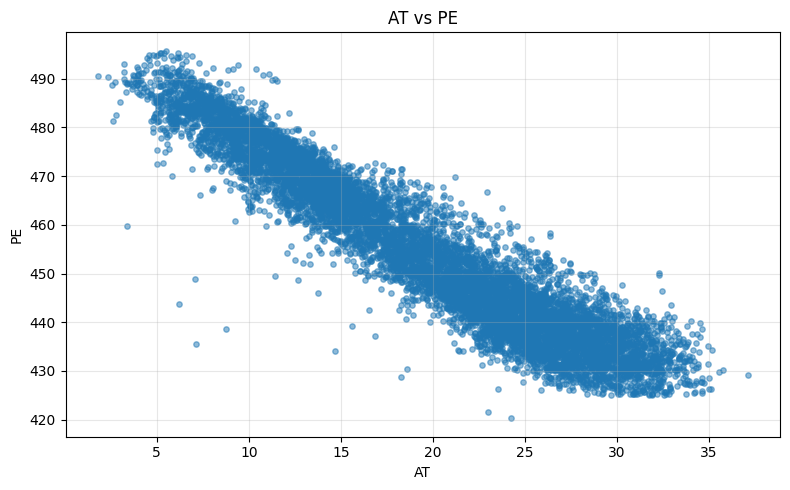

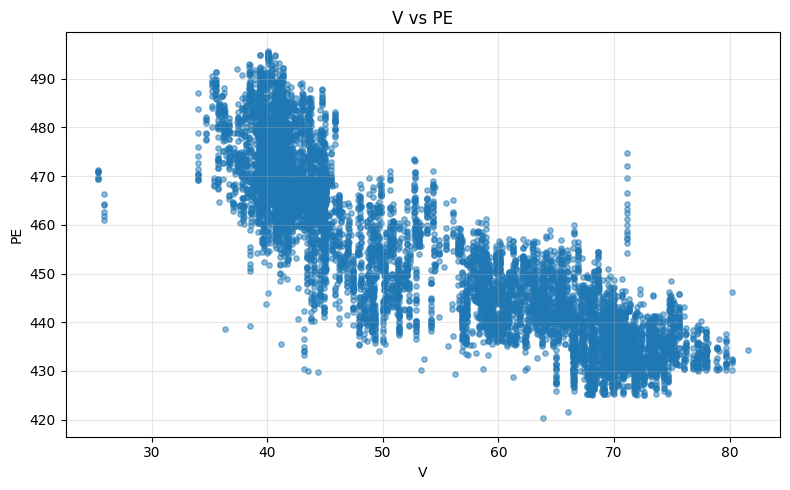

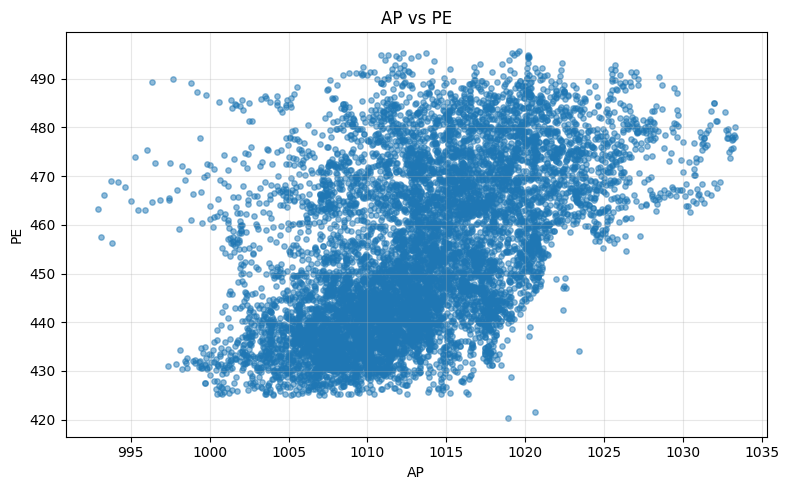

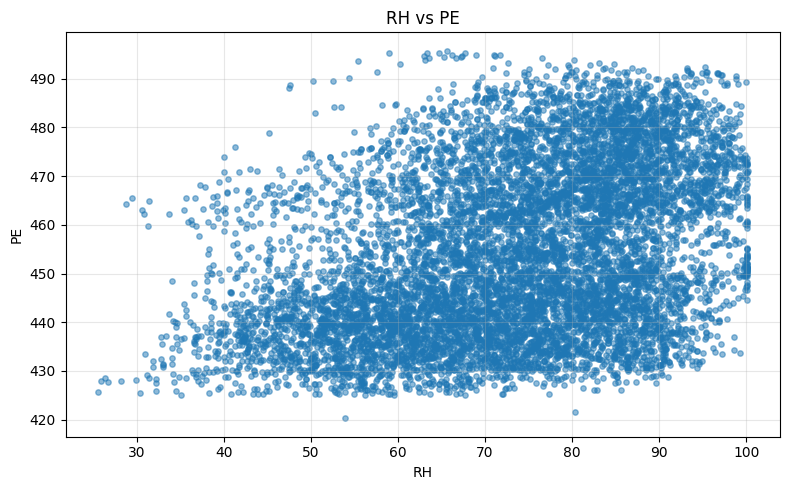

In [93]:
plot_features_against_target(
    X_all,
    y_all,
    feature_names,
    target_name
)

In [94]:
def train_validation_split(X, y, validation_ratio=0.20, seed=42):

    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    rng = np.random.default_rng(seed)
    indices = rng.permutation(len(y))

    validation_size = int(len(y) * validation_ratio)

    validation_indices = indices[:validation_size]
    training_indices = indices[validation_size:]

    X_train = X[training_indices]
    y_train = y[training_indices]

    X_val = X[validation_indices]
    y_val = y[validation_indices]

    return X_train, X_val, y_train, y_val


In [95]:
X_train_raw, X_val_raw, y_train, y_val = train_validation_split(
    X_all,
    y_all,
    validation_ratio=0.20,
    seed=42
)

print("Training samples:", len(y_train))
print("Validation samples:", len(y_val))


Training samples: 7655
Validation samples: 1913


In [96]:
#feature scaling
def process_multivariable_data(
    X_train,
    X_val=None,
    feature_scaling=False
):

    X_train = np.asarray(X_train, dtype=float)

    scale_params = {
        "scaled": feature_scaling,
        "mean": np.zeros(X_train.shape[1]),
        "std": np.ones(X_train.shape[1])
    }

    X_train_processed = X_train.copy()

    if X_val is not None:
        X_val = np.asarray(X_val, dtype=float)
        X_val_processed = X_val.copy()
    else:
        X_val_processed = None


    if feature_scaling:

        mean = np.mean(X_train, axis=0)
        std = np.std(X_train, axis=0)

        std[std == 0] = 1.0

        X_train_processed = (X_train - mean) / std

        if X_val is not None:
            X_val_processed = (X_val - mean) / std

        scale_params["mean"] = mean
        scale_params["std"] = std



    X_train_processed = np.column_stack((   # 1 add kora dummy hishabe
        np.ones(len(X_train_processed)),
        X_train_processed
    ))

    if X_val_processed is not None:
        X_val_processed = np.column_stack((
            np.ones(len(X_val_processed)),
            X_val_processed
        ))

    return X_train_processed, X_val_processed, scale_params


In [97]:
def compute_cost(X, y, theta):

    m = len(y)

    predictions = X.dot(theta)
    errors = predictions - y

    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    return cost


In [98]:
def gradient_descent(
    X_train,
    y_train,
    theta,
    learning_rate,
    iterations,
    X_val=None,
    y_val=None
):

    m = len(y_train)

    train_cost_history = []
    val_cost_history = []

    best_theta = theta.copy()
    best_val_cost = np.inf
    best_iteration = -1

    for i in range(iterations):

        predictions = X_train.dot(theta)

        errors = predictions - y_train

        gradient = (1 / m) * X_train.T.dot(errors)

        theta = theta - learning_rate * gradient

        train_cost = compute_cost(X_train, y_train, theta)

        train_cost_history.append(train_cost)

        if X_val is not None and y_val is not None:

            val_cost = compute_cost(X_val, y_val, theta)
            val_cost_history.append(val_cost)

            if val_cost < best_val_cost:
                best_val_cost = val_cost
                best_theta = theta.copy()
                best_iteration = i + 1

    # validation na thakle use final theta
    if X_val is None or y_val is None:
        best_theta = theta.copy()
        best_val_cost = None
        best_iteration = iterations

    return (
        theta,
        train_cost_history,
        val_cost_history,
        best_theta,
        best_val_cost,
        best_iteration
    )


In [99]:
def train(
    X_train,
    y_train,
    X_val=None,
    y_val=None,
    learning_rate=0.01,
    iterations=1000
):

    n = X_train.shape[1]

    # Initialize theta with zeros
    theta = np.zeros(n)

    return gradient_descent(
        X_train,
        y_train,
        theta,
        learning_rate,
        iterations,
        X_val,
        y_val
    )

In [100]:
def plot_error_curves(
    train_cost_history,
    val_cost_history,
    title="Training and Validation Error"
):


    plt.figure(figsize=(8, 5))

    iterations = range(1, len(train_cost_history) + 1)

    plt.plot(
        iterations,
        train_cost_history,
        label="Training Error"
    )

    if len(val_cost_history) > 0:
        plt.plot(
            iterations,
            val_cost_history,
            label="Validation Error"
        )

    plt.xlabel("Iterations")
    plt.ylabel("Cost")
    plt.title(title)

    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [101]:
def original_scale_parameters(theta, scale_params):

    if not scale_params["scaled"]:
        return theta.copy()

    mean = scale_params["mean"]
    std = scale_params["std"]

    beta = np.zeros_like(theta)

    beta[1:] = theta[1:] / std
    beta[0] = theta[0] - np.sum(theta[1:] * mean / std)

    return beta

In [102]:
def print_multivariable_parameters(theta, feature_names, scale_params):

    print("=" * 60)
    print("LEARNED MODEL PARAMETERS")
    print("=" * 60)

    print(f"theta_0 = {theta[0]:.6f}")

    for j, name in enumerate(feature_names, start=1):
        print(f"theta_{j} ({name}) = {theta[j]:.6f}")

    beta = original_scale_parameters(theta, scale_params)

    print("\nOriginal feature scale:")
    print(f"Intercept = {beta[0]:.6f}")

    for j, name in enumerate(feature_names, start=1):
        print(f"Coefficient of {name} = {beta[j]:.6f}")

    print("\nOriginal-scale equation:")

    equation = f"PE_hat = {beta[0]:.6f}"

    for j, name in enumerate(feature_names, start=1):
        equation += f" + ({beta[j]:.6f})*{name}"

    print(equation)
    print("=" * 60)



### WITHOUT FEATURE SCALING


In [103]:

X_train_no_scale, X_val_no_scale, params_no_scale = process_multivariable_data(
    X_train_raw,
    X_val_raw,
    feature_scaling=False
)

raw_learning_rate = 0.0000005
raw_iterations = 5000

(
    theta_raw_final,
    train_cost_raw,
    val_cost_raw,
    theta_raw_best,
    best_val_raw,
    best_iter_raw
) = train(
    X_train_no_scale,
    y_train,
    X_val_no_scale,
    y_val,
    learning_rate=raw_learning_rate,
    iterations=raw_iterations
)

best_train_raw = compute_cost(
    X_train_no_scale,
    y_train,
    theta_raw_best
)

print("Training completed WITHOUT feature scaling.")
print(f"Learning rate = {raw_learning_rate}")
print(f"Best iteration = {best_iter_raw}")
print(f"Training cost at best iteration = {best_train_raw:.6f}")
print(f"Best validation cost = {best_val_raw:.6f}")

print_multivariable_parameters(
    theta_raw_best,
    feature_names,
    params_no_scale
)


Training completed WITHOUT feature scaling.
Learning rate = 5e-07
Best iteration = 5000
Training cost at best iteration = 54.835725
Best validation cost = 54.837414
LEARNED MODEL PARAMETERS
theta_0 = 0.000381
theta_1 (AT) = -0.205242
theta_2 (V) = -0.313458
theta_3 (AP) = 0.457404
theta_4 (RH) = 0.162300

Original feature scale:
Intercept = 0.000381
Coefficient of AT = -0.205242
Coefficient of V = -0.313458
Coefficient of AP = 0.457404
Coefficient of RH = 0.162300

Original-scale equation:
PE_hat = 0.000381 + (-0.205242)*AT + (-0.313458)*V + (0.457404)*AP + (0.162300)*RH


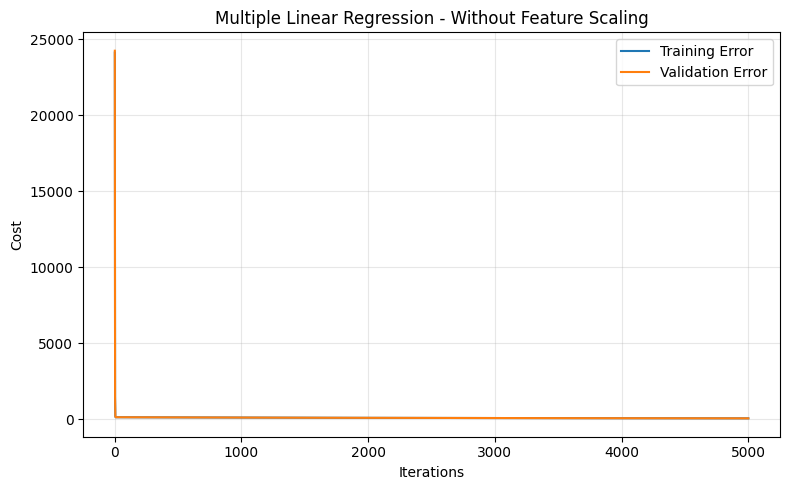

In [104]:
plot_error_curves(
    train_cost_raw,
    val_cost_raw,
    title="Multiple Linear Regression - Without Feature Scaling"
)


### With Feature add

In [105]:
X_train_scaled, X_val_scaled, params_scaled = process_multivariable_data(
    X_train_raw,
    X_val_raw,
    feature_scaling=True
)

scaled_learning_rate = 0.05
scaled_iterations = 1000

(
    theta_scaled_final,
    train_cost_scaled,
    val_cost_scaled,
    theta_scaled_best,
    best_val_scaled,
    best_iter_scaled
) = train(
    X_train_scaled,
    y_train,
    X_val_scaled,
    y_val,
    learning_rate=scaled_learning_rate,
    iterations=scaled_iterations
)

best_train_scaled = compute_cost(
    X_train_scaled,
    y_train,
    theta_scaled_best
)

print("Training completed WITH feature scaling.")
print(f"Learning rate = {scaled_learning_rate}")
print(f"Best iteration = {best_iter_scaled}")
print(f"Training cost at best iteration = {best_train_scaled:.6f}")
print(f"Best validation cost = {best_val_scaled:.6f}")

print_multivariable_parameters(
    theta_scaled_best,
    feature_names,
    params_scaled
)


Training completed WITH feature scaling.
Learning rate = 0.05
Best iteration = 1000
Training cost at best iteration = 10.482488
Best validation cost = 10.007414
LEARNED MODEL PARAMETERS
theta_0 = 454.248138
theta_1 (AT) = -14.543817
theta_2 (V) = -3.114429
theta_3 (AP) = 0.428379
theta_4 (RH) = -2.263662

Original feature scale:
Intercept = 443.666362
Coefficient of AT = -1.951346
Coefficient of V = -0.245150
Coefficient of AP = 0.072762
Coefficient of RH = -0.154903

Original-scale equation:
PE_hat = 443.666362 + (-1.951346)*AT + (-0.245150)*V + (0.072762)*AP + (-0.154903)*RH


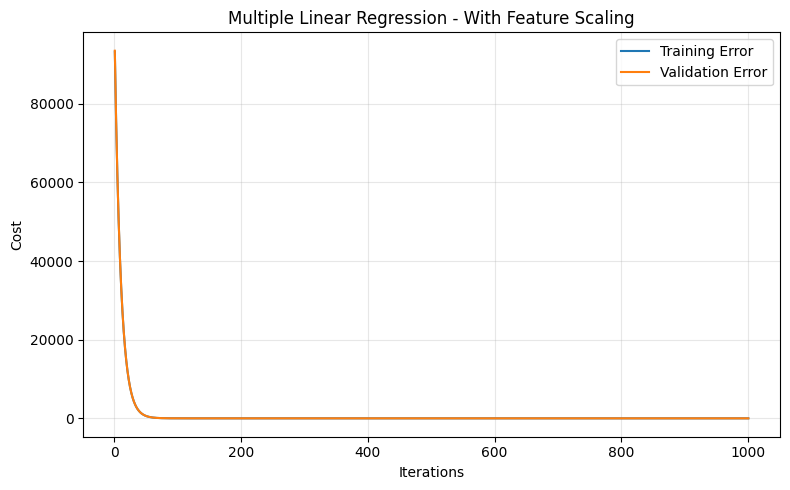

In [106]:
plot_error_curves(
    train_cost_scaled,
    val_cost_scaled,
    title="Multiple Linear Regression - With Feature Scaling"
)


In [107]:
comparison = pd.DataFrame({
    "Setting": [
        "Without Feature Scaling",
        "With Feature Scaling"
    ],
    "Learning Rate": [
        raw_learning_rate,
        scaled_learning_rate
    ],
    "Iterations": [
        raw_iterations,
        scaled_iterations
    ],
    "Best Training Cost": [
        best_train_raw,
        best_train_scaled
    ],
    "Best Validation Cost": [
        best_val_raw,
        best_val_scaled
    ],
    "Best Iteration": [
        best_iter_raw,
        best_iter_scaled
    ]
})

print(comparison.to_string(index=False))

                Setting  Learning Rate  Iterations  Best Training Cost  Best Validation Cost  Best Iteration
Without Feature Scaling   5.000000e-07        5000           54.835725             54.837414            5000
   With Feature Scaling   5.000000e-02        1000           10.482488             10.007414            1000


### Poly regression data

In [108]:
def load_polynomial_data(filename):

    data = pd.read_csv(filename)

    x = data["x"].values.astype(float)
    y = data["y"].values.astype(float)

    return x, y, data

In [109]:
def load_polynomial_data(filename):

    data = pd.read_csv(filename, header=None)
    if data.shape[1] >= 2:
        data.columns = ['x', 'y'] + list(data.columns[2:])
    else:
        raise ValueError("CSV file does not contain enough columns for 'x' and 'y'")

    x = data["x"].values.astype(float)
    y = data["y"].values.astype(float)

    return x, y, data

x_poly_all, y_poly_all, poly_data = load_polynomial_data(
    "data_02b.csv"
)

print("Polynomial-regression dataset loaded.")
print("Number of samples:", len(y_poly_all))

print("\nFirst 5 rows:")
print(poly_data.head())

Polynomial-regression dataset loaded.
Number of samples: 392

First 5 rows:
     x     y
0  130  18.0
1  165  15.0
2  150  18.0
3  150  16.0
4  140  17.0


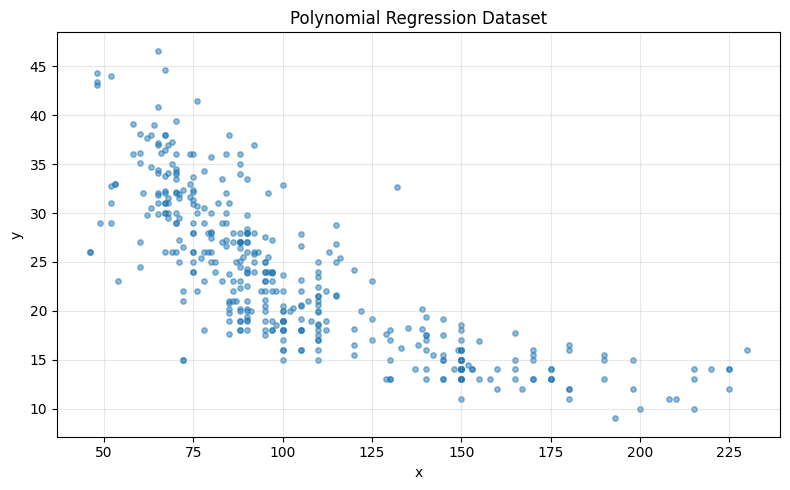

In [110]:
plt.figure(figsize=(8, 5))

plt.scatter(
    x_poly_all,
    y_poly_all,
    s=15,
    alpha=0.5
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Polynomial Regression Dataset")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#Polynomial feature add

In [111]:

def process_polynomial_data(
    x_train,
    degree,
    x_val=None,
    scale_params=None
):


    x_train = np.asarray(x_train, dtype=float)

    if scale_params is None:
        mean = np.mean(x_train)
        std = np.std(x_train)

        if std == 0:
            std = 1.0

        scale_params = {
            "mean": mean,
            "std": std
        }
    else:
        mean = scale_params["mean"]
        std = scale_params["std"]

    z_train = (x_train - mean) / std

    X_train = np.column_stack([
        z_train ** power
        for power in range(degree + 1)
    ])

    X_val = None

    if x_val is not None:
        x_val = np.asarray(x_val, dtype=float)
        z_val = (x_val - mean) / std

        X_val = np.column_stack([
            z_val ** power
            for power in range(degree + 1)
        ])

    return X_train, X_val, scale_params

In [112]:
def polynomial_original_coefficients(theta, scale_params):

    mean = scale_params["mean"]
    std = scale_params["std"]

    # z = -mean/std + (1/std)x
    z_polynomial = np.polynomial.Polynomial([
        -mean / std,
        1 / std
    ])

    original_polynomial = np.polynomial.Polynomial([0.0])

    for power, coefficient in enumerate(theta):
        original_polynomial = (
            original_polynomial
            + coefficient * (z_polynomial ** power)
        )

    return original_polynomial.coef

## Train

In [113]:
x_poly_train, x_poly_val, y_poly_train, y_poly_val = train_validation_split(
    x_poly_all.reshape(-1, 1),
    y_poly_all,
    validation_ratio=0.20,
    seed=42
)

x_poly_train = x_poly_train.ravel()
x_poly_val = x_poly_val.ravel()

print("Training samples:", len(y_poly_train))
print("Validation samples:", len(y_poly_val))


Training samples: 314
Validation samples: 78


## d =1,2,3

In [114]:
polynomial_results = {}

degrees = [1, 2, 3]

for degree in degrees:

    X_poly_train, X_poly_val, poly_scale = process_polynomial_data(
        x_poly_train,
        degree,
        x_val=x_poly_val
    )

    (
        theta_final,
        train_history,
        val_history,
        theta_best,
        best_val_cost,
        best_iteration
    ) = train(
        X_poly_train,
        y_poly_train,
        X_poly_val,
        y_poly_val,
        learning_rate=0.03,
        iterations=2000
    )

    best_train_cost = compute_cost(
        X_poly_train,
        y_poly_train,
        theta_best
    )

    original_coefficients = polynomial_original_coefficients(
        theta_best,
        poly_scale
    )

    polynomial_results[degree] = {
        "theta": theta_best,
        "scale_params": poly_scale,
        "train_history": train_history,
        "val_history": val_history,
        "training_cost": best_train_cost,
        "validation_cost": best_val_cost,
        "best_iteration": best_iteration,
        "original_coefficients": original_coefficients
    }

    print("=" * 55)
    print(f"Degree d = {degree}")
    print(f"Best iteration = {best_iteration}")
    print(f"Training cost = {best_train_cost:.6f}")
    print(f"Validation cost = {best_val_cost:.6f}")
    print("Theta (standardized x basis) =", theta_best)
    print("Original x coefficients =", original_coefficients)


Degree d = 1
Best iteration = 1100
Training cost = 11.546373
Validation cost = 13.728353
Theta (standardized x basis) = [23.00254777 -6.00516116]
Original x coefficients = [39.59185498 -0.15546132]
Degree d = 2
Best iteration = 323
Training cost = 9.211059
Validation cost = 10.668958
Theta (standardized x basis) = [21.05023698 -8.02213582  1.89594931]
Original x coefficients = [ 5.76802991e+01 -4.78856868e-01  1.27063874e-03]
Degree d = 3
Best iteration = 306
Training cost = 9.432202
Validation cost = 10.349727
Theta (standardized x basis) = [20.38169675 -7.48959747  2.81383229 -0.37994927]
Original x coefficients = [ 7.05554678e+01 -8.21547946e-01  3.99609895e-03 -6.59202224e-06]


In [115]:
best_degree = min(
    polynomial_results,
    key=lambda d: polynomial_results[d]["validation_cost"]
)

best_result = polynomial_results[best_degree]

print("Best polynomial degree:", best_degree)
print(f"Best validation cost: {best_result['validation_cost']:.6f}")
print(f"Training cost: {best_result['training_cost']:.6f}")

print("\nLearned parameters for best degree")
print("(standardized x basis):")

for j, value in enumerate(best_result["theta"]):
    print(f"theta_{j} = {value:.6f}")

print("\nEquivalent parameters on original x scale:")

for j, value in enumerate(best_result["original_coefficients"]):
    print(f"a_{j} = {value:.6f}")


Best polynomial degree: 3
Best validation cost: 10.349727
Training cost: 9.432202

Learned parameters for best degree
(standardized x basis):
theta_0 = 20.381697
theta_1 = -7.489597
theta_2 = 2.813832
theta_3 = -0.379949

Equivalent parameters on original x scale:
a_0 = 70.555468
a_1 = -0.821548
a_2 = 0.003996
a_3 = -0.000007


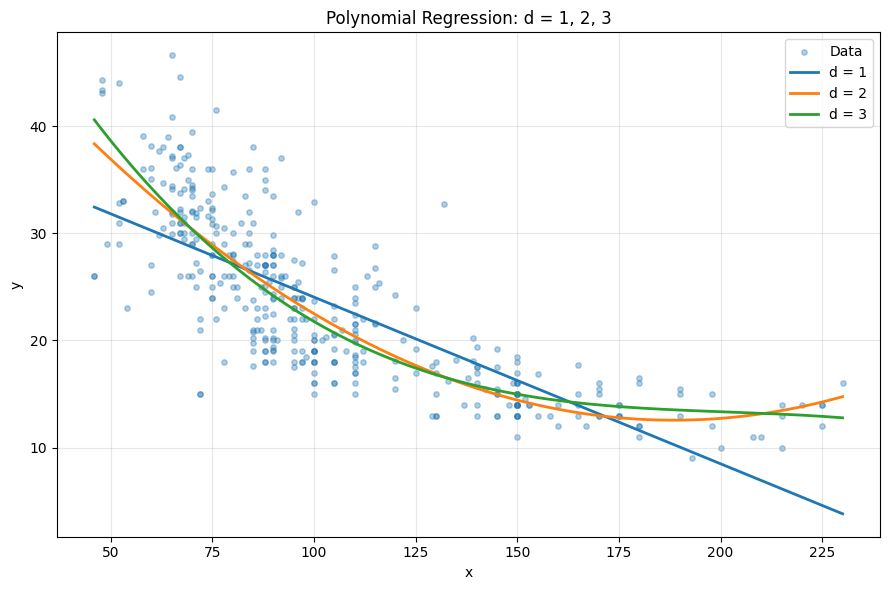

In [116]:

plt.figure(figsize=(9, 6))

plt.scatter(
    x_poly_all,
    y_poly_all,
    s=15,
    alpha=0.35,
    label="Data"
)

x_curve = np.linspace(
    x_poly_all.min(),
    x_poly_all.max(),
    500
)

for degree in degrees:

    result = polynomial_results[degree]

    _, X_curve, _ = process_polynomial_data(
        x_poly_train,
        degree,
        x_val=x_curve,
        scale_params=result["scale_params"]
    )

    y_curve = X_curve.dot(result["theta"])

    plt.plot(
        x_curve,
        y_curve,
        linewidth=2,
        label=f"d = {degree}"
    )

plt.xlabel("x")
plt.ylabel("y")
plt.title("Polynomial Regression: d = 1, 2, 3")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


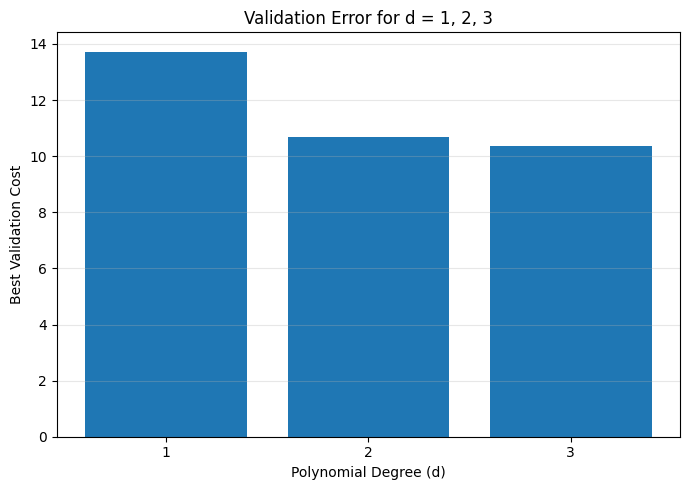

In [117]:

validation_errors = [
    polynomial_results[d]["validation_cost"]
    for d in degrees
]

plt.figure(figsize=(7, 5))

plt.bar(
    [str(d) for d in degrees],
    validation_errors
)

plt.xlabel("Polynomial Degree (d)")
plt.ylabel("Best Validation Cost")
plt.title("Validation Error for d = 1, 2, 3")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


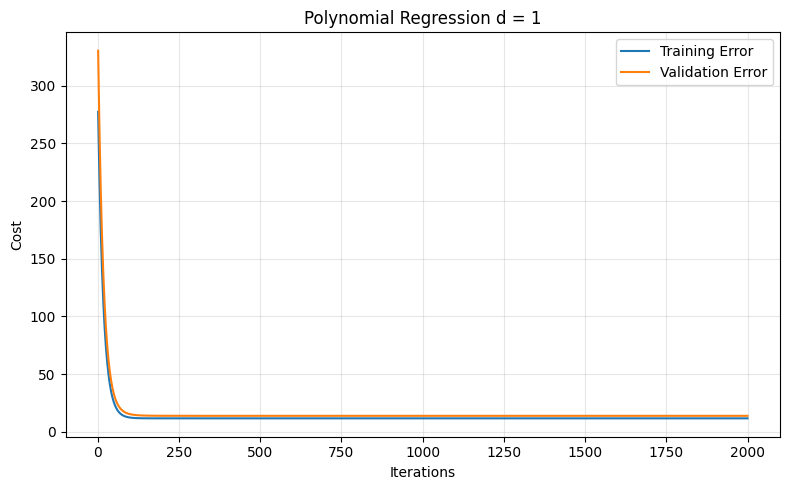

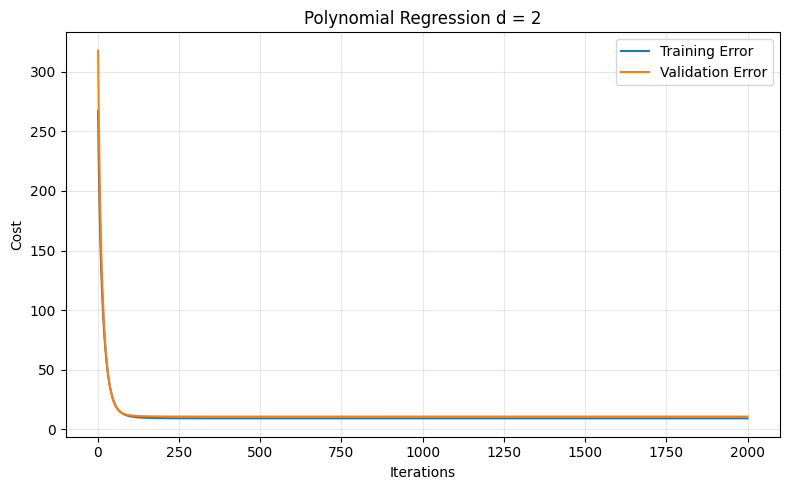

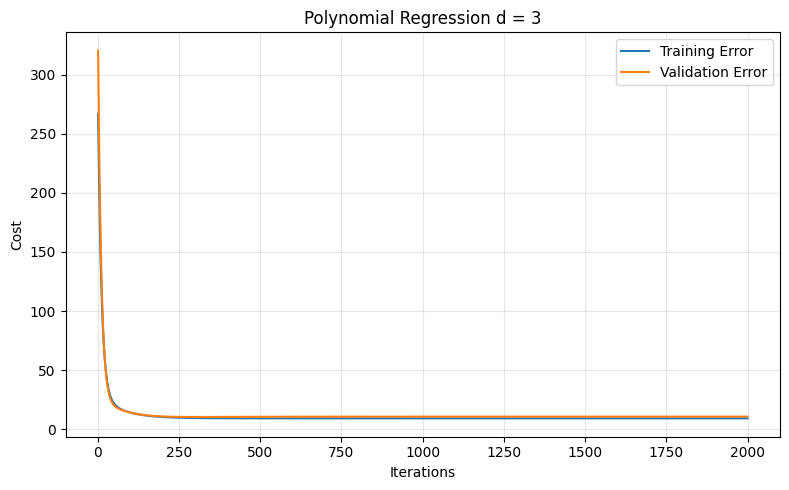

In [118]:

for degree in degrees:

    result = polynomial_results[degree]

    plot_error_curves(
        result["train_history"],
        result["val_history"],
        title=f"Polynomial Regression d = {degree}"
    )
